In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification, load_digits
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)

def ve_vung(mh, X, y, ax, tieu_de="", le=True):
    """Vẽ vùng quyết định, mép lề (nếu có) và dữ liệu cho bài toán 2 cột."""
    X = np.asarray(X)
    x1 = np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 300)
    x2 = np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 300)
    g1, g2 = np.meshgrid(x1, x2)
    f = mh.decision_function(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, f, levels=[-1e9, 0, 1e9], colors=["#c9d4e6", "#f5c6ca"])
    ax.contour(g1, g2, f, levels=[0], colors="k", linewidths=1.5)
    if le:
        ax.contour(g1, g2, f, levels=[-1, 1], colors="k", linestyles="--", linewidths=.8)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#08306b", s=12)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#cb181d", marker="^", s=12)
    ax.set_title(tieu_de)

# ---- Tải tệp dữ liệu lên (bỏ qua nếu tệp đã có trong data/) ----
CAN_CO = ["sinh_vien.csv", "sinh_vien_mo_rong.csv", "hai_vang_trang.csv"]
thieu = [t for t in CAN_CO if not os.path.exists(f"data/{t}")]
if thieu:
    try:
        from google.colab import files
        print("Hay chon cac tep CSV:", thieu)
        for ten, noi_dung in files.upload().items():
            with open(f"data/{os.path.basename(ten)}", "wb") as f:
                f.write(noi_dung)
    except ImportError:
        print("Khong chay tren Colab: hay tu dat cac tep vao thu muc data/")

con_thieu = [t for t in CAN_CO if not os.path.exists(f"data/{t}")]
print("Cac tep trong data/:", os.listdir("data"))
if con_thieu:
    print("CHUA CO:", con_thieu, "-> cac muc dung tep nay se bao loi cho den khi tai len.")

Hay chon cac tep CSV: ['sinh_vien.csv', 'sinh_vien_mo_rong.csv', 'hai_vang_trang.csv']


Saving hai_vang_trang.csv to hai_vang_trang.csv
Saving sinh_vien.csv to sinh_vien.csv
Saving sinh_vien_mo_rong.csv to sinh_vien_mo_rong.csv
Cac tep trong data/: ['sinh_vien_mo_rong.csv', 'sinh_vien.csv', 'hai_vang_trang.csv']


##2.


w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
  diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
  diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
  diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
  w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


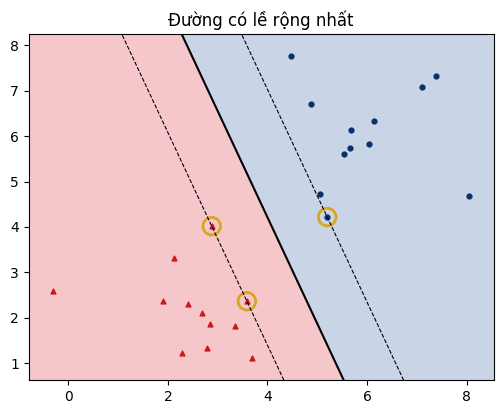

In [2]:
# 24 điểm, hai cụm tách hẳn nhau
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y            # lớp 1 là cụm dưới bên trái

svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()

print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"  diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
          f" lop {y[i]}, f(x) = {f:+.3f}")
print()

f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
print(f"|f(x)| nho nhat cua cac diem khac: {np.abs(f_tat_ca[ngoai]).min():.3f}")
print()

# Học lại chỉ với các vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000).fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
print(f"  w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {chi_sv.intercept_[0]:.3f}")
print()

# Dự đoán hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi), svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

# Hình minh hoạ
fig, ax = plt.subplots(figsize=(6, 4.5))
ve_vung(svm, X, y, ax, "Đường có lề rộng nhất")
ax.scatter(X[svm.support_, 0], X[svm.support_, 1], s=160, facecolors="none",
           edgecolors="goldenrod", linewidths=2)
plt.show()

## 3.

Tap hoc co 90 ban
     C  so vecto HT  do rong le  tap hoc  tap kiem tra
   0.01         74        3.84  0.8556  0.8667
    0.1         44        1.70  0.8889  0.9000
      1         31        1.29  0.8778  0.9000
     10         28        1.06  0.9000  0.9000
    100         27        1.05  0.9000  0.9000



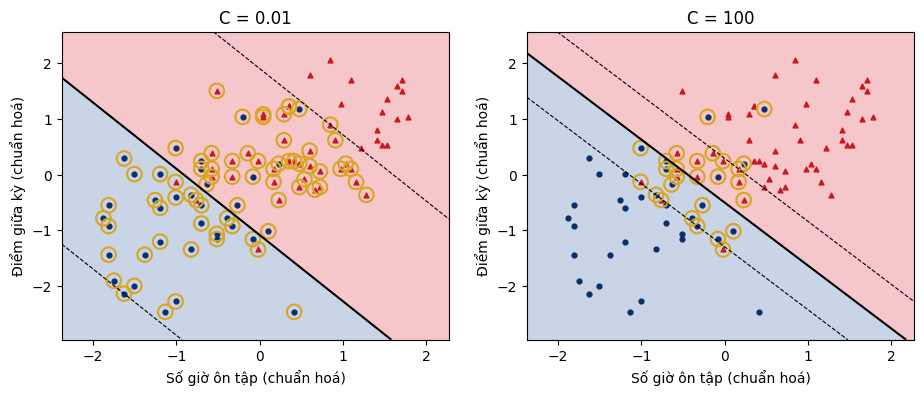

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa     : 0.6000
  Co chuan hoa        : 0.9000


In [3]:
df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

print("Tap hoc co", len(X_tr), "ban")
print("     C  so vecto HT  do rong le  tap hoc  tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    s = mh[-1]
    le = 2 / np.linalg.norm(s.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {C:6} {len(s.support_):10d} {le:11.2f}  {a_hoc:.4f}  {a_kt:.4f}")
print()

# Hình: C = 0.01 và C = 100 (vẽ trên dữ liệu đã chuẩn hoá)
sc = StandardScaler().fit(X_tr)
Z = sc.transform(X_tr)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, C in zip(axs, [0.01, 100]):
    m = SVC(kernel="linear", C=C).fit(Z, y_tr)
    ve_vung(m, Z, y_tr.values, ax, f"C = {C}")
    ax.scatter(Z[m.support_, 0], Z[m.support_, 1], s=110, facecolors="none",
               edgecolors="goldenrod", linewidths=1.5)
    ax.set_xlabel("Số giờ ôn tập (chuẩn hoá)"); ax.set_ylabel("Điểm giữa kỳ (chuẩn hoá)")
plt.show()

# Bộ mở rộng có thêm cột chi tiêu (nghìn đồng)
df3 = pd.read_csv("data/sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa     : {accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa        : {accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

## 4.

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000



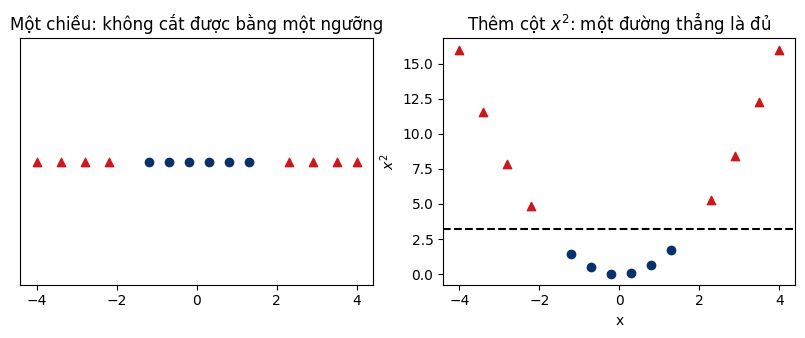

Hai vang trang, accuracy tren tap kiem tra
  SVM kernel tuyen tinh      0.8667
  SVM kernel da thuc bac 3   0.8667
  SVM kernel RBF             0.9200
  Hoi quy logistic           0.8533
  KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


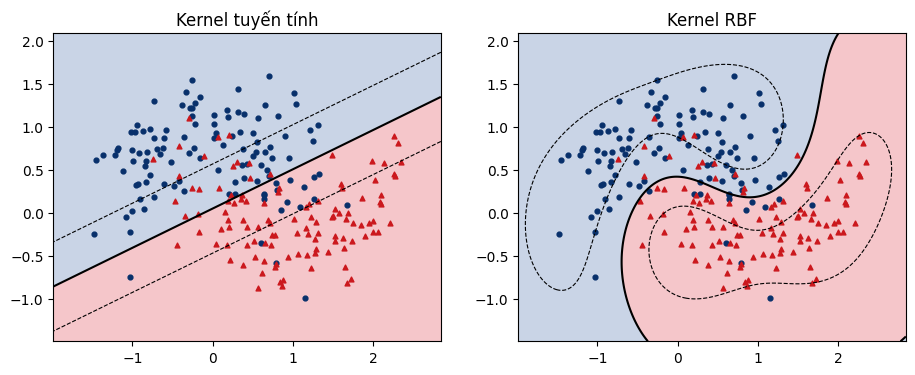

In [4]:
# Phần 1: dữ liệu một chiều, lớp 1 nằm giữa
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y1 = (np.abs(x) < 1.8).astype(int)

tot = max(((x <= t).astype(int) == y1).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

X_moi = np.c_[x, x ** 2]
svm_nc = SVC(kernel="linear", C=1000).fit(X_moi, y1)
print(f"Them cot x^2, SVM tuyen tinh dung {svm_nc.score(X_moi, y1):.4f}")
print()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].scatter(x[y1 == 0], np.zeros((y1 == 0).sum()), c="#cb181d", marker="^")
axs[0].scatter(x[y1 == 1], np.zeros((y1 == 1).sum()), c="#08306b")
axs[0].set_title("Một chiều: không cắt được bằng một ngưỡng"); axs[0].set_yticks([])
axs[1].scatter(x[y1 == 0], x[y1 == 0] ** 2, c="#cb181d", marker="^")
axs[1].scatter(x[y1 == 1], x[y1 == 1] ** 2, c="#08306b")
axs[1].axhline(3.2, c="k", ls="--")
axs[1].set_title("Thêm cột $x^2$: một đường thẳng là đủ"); axs[1].set_xlabel("x"); axs[1].set_ylabel("$x^2$")
plt.show()

# Phần 2: hai vầng trăng
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

mo_hinh = {
    "SVM kernel tuyen tinh":    SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF":           SVC(kernel="rbf"),
    "Hoi quy logistic":         LogisticRegression(),
    "KNN, k = 13":              KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    print(f"  {ten:26s} {accuracy_score(y_te, mh.predict(X_te)):.4f}")
print()
rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_), "tren", len(X_tr), "diem hoc")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ve_vung(mo_hinh["SVM kernel tuyen tinh"], X_tr, y_tr.values, axs[0], "Kernel tuyến tính")
ve_vung(rbf, X_tr, y_tr.values, axs[1], "Kernel RBF")
plt.show()

## 5.



gamma  tap hoc  tap kiem tra  so vecto HT
   0.1  0.8356   0.8533        113
     1  0.8711   0.9200        88
    10  0.8978   0.9067        128
   100  0.9422   0.8133        217



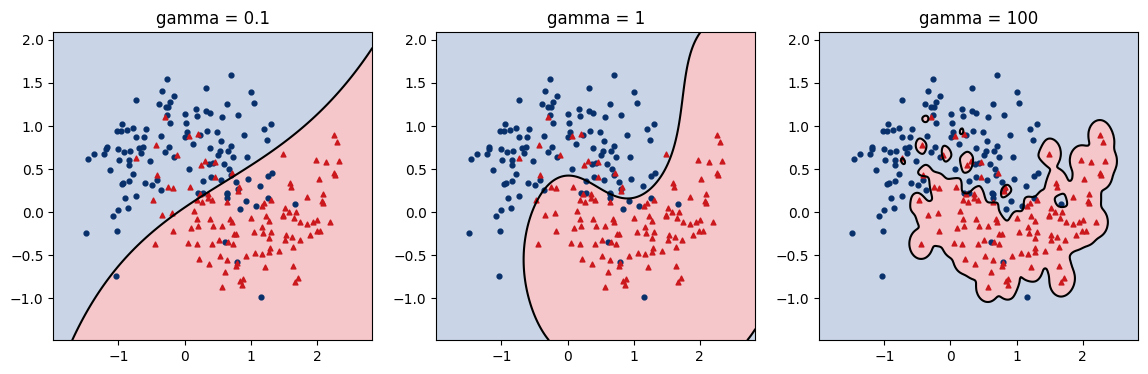

Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


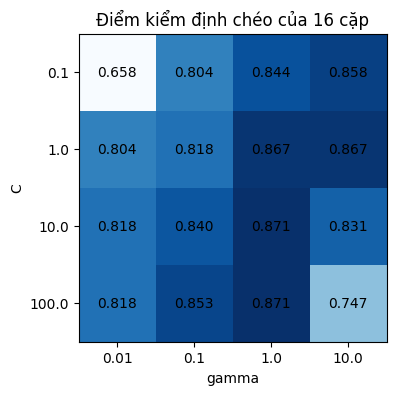

In [5]:
print("gamma  tap hoc  tap kiem tra  so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {g:5}  {a_hoc:.4f}   {a_kt:.4f}        {len(mh.support_)}")
print()

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, g in zip(axs, [0.1, 1, 100]):
    m = SVC(kernel="rbf", C=1, gamma=g).fit(X_tr, y_tr)
    ve_vung(m, X_tr, y_tr.values, ax, f"gamma = {g}", le=False)
plt.show()

# Dò lưới
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
pv = bang.pivot(index="C", columns="gamma", values="diem")
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(pv.round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(pv.values, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(pv.columns)
ax.set_yticks(range(4)); ax.set_yticklabels(pv.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center")
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("Điểm kiểm định chéo của 16 cặp")
plt.show()

## 6.

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778
  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


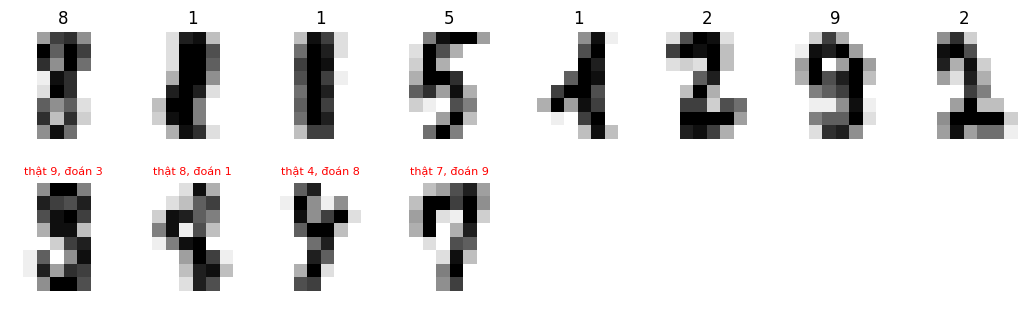

In [6]:
X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y)

svm_d = SVC(kernel="rbf").fit(Xd_tr, yd_tr)
du_doan = svm_d.predict(Xd_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(yd_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm_d.support_), "tren", len(Xd_tr), "anh")
sai = np.flatnonzero(du_doan != yd_te)
print("So anh doan sai:", len(sai), "tren", len(yd_te))
for i in sai:
    print(f"  anh {i:3d}: that la {yd_te[i]}, doan la {du_doan[i]}")
print()

mo_hinh_d = {
    "SVM co chuan hoa":      make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5":            KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh_d.items():
    mh.fit(Xd_tr, yd_tr)
    print(f"  {ten:22s} {accuracy_score(yd_te, mh.predict(Xd_te)):.4f}")

fig, axs = plt.subplots(2, 8, figsize=(13, 3.6))
for k in range(8):
    axs[0, k].imshow(Xd_tr[k].reshape(8, 8), cmap="gray_r"); axs[0, k].set_title(yd_tr[k]); axs[0, k].axis("off")
for k in range(8):
    axs[1, k].axis("off")
for k, i in enumerate(sai[:8]):
    axs[1, k].imshow(Xd_te[i].reshape(8, 8), cmap="gray_r")
    axs[1, k].set_title(f"thật {yd_te[i]}, đoán {du_doan[i]}", color="red", fontsize=8)
plt.show()

## 7. Bài tập

In [7]:
# Học lại mô hình ở mục 2 để lấy w1, w2, b
X2, y2 = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0)
y2 = 1 - y2
m2 = SVC(kernel="linear", C=1000).fit(X2, y2)
w = m2.coef_[0]; b = m2.intercept_[0]
norm_w = np.sqrt(w[0] ** 2 + w[1] ** 2)

def f_tay(x1, x2):
    return w[0] * x1 + w[1] * x2 + b          # chỉ nhân và cộng

print(f"w1 = {w[0]:.4f}, w2 = {w[1]:.4f}, b = {b:.4f}, ||w|| = {norm_w:.4f}")
print("\nHai diem moi:")
for (a, c) in [(3, 3), (5, 4.5)]:
    f = f_tay(a, c)
    print(f"  ({a}, {c}): f = {f:+.3f}, khoang cach = |f|/||w|| = {abs(f)/norm_w:.4f}")
print("\nBa vecto ho tro:")
for i in m2.support_:
    f = f_tay(X2[i, 0], X2[i, 1])
    print(f"  diem {i:2d}: f = {f:+.3f}, khoang cach = {abs(f)/norm_w:.4f}")
print(f"\nNua do rong le = 1/||w|| = {1/norm_w:.4f}")

w1 = -0.8314, w2 = -0.3549, b = 4.8204, ||w|| = 0.9039

Hai diem moi:
  (3, 3): f = +1.262, khoang cach = |f|/||w|| = 1.3958
  (5, 4.5): f = -0.933, khoang cach = |f|/||w|| = 1.0325

Ba vecto ho tro:
  diem 18: f = -1.000, khoang cach = 1.1064
  diem 10: f = +1.000, khoang cach = 1.1062
  diem 13: f = +1.000, khoang cach = 1.1065

Nua do rong le = 1/||w|| = 1.1063


**Giải thích:** vectơ hỗ trợ nằm đúng trên mép lề nên $|f(x)|=1$. Khoảng cách tới ranh giới là $|f|/\|w\| = 1/\|w\|$. Độ rộng lề là $2/\|w\|$ (từ mép −1 tới mép +1), nên khoảng cách từ vectơ hỗ trợ tới ranh giới đúng bằng một nửa độ rộng lề.
Điểm (5, 4.5) có $|f|<1$ nên cách ranh giới chưa tới nửa lề, tức nằm trong lề.

Ban dau          : w1 = -0.831, w2 = -0.355, b = 4.820, so vecto HT = 3, sai tren tap hoc = 0
Them (-1, -1) l.1 : w1 = -0.831, w2 = -0.355, b = 4.820, so vecto HT = 3, sai tren tap hoc = 0
Them (4.5, 4) l.1 : w1 = -2.603, w2 = -0.807, b = 15.941, so vecto HT = 2, sai tren tap hoc = 0

A co doi duong ranh gioi khong? False
B co doi duong ranh gioi khong? True


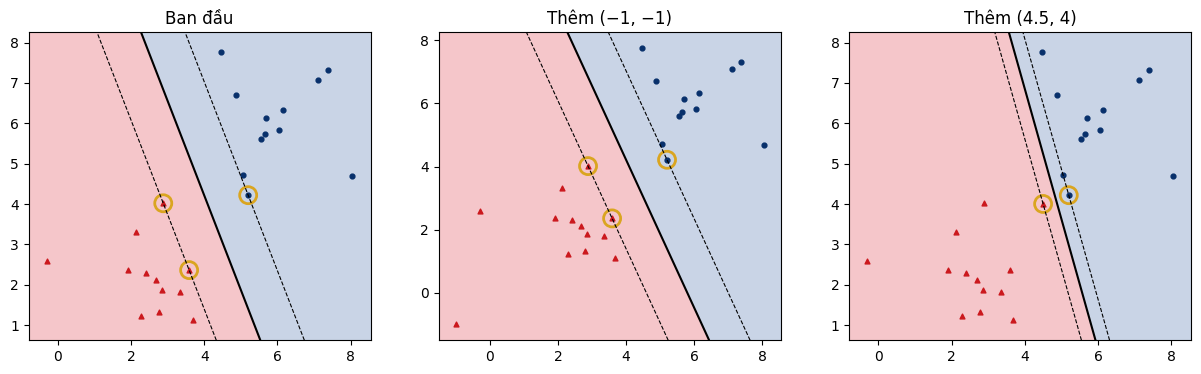

In [8]:
def hoc_va_in(X_, y_, nhan):
    m = SVC(kernel="linear", C=1000).fit(X_, y_)
    w_, b_ = m.coef_[0], m.intercept_[0]
    print(f"{nhan}: w1 = {w_[0]:.3f}, w2 = {w_[1]:.3f}, b = {b_:.3f}, "
          f"so vecto HT = {len(m.support_)}, sai tren tap hoc = {(m.predict(X_) != y_).sum()}")
    return m

m_goc = hoc_va_in(X2, y2, "Ban dau          ")

# Trường hợp A: điểm lớp 1 ở (-1, -1), rất xa ranh giới, đúng phía lớp 1
XA = np.vstack([X2, [-1, -1]]); yA = np.append(y2, 1)
mA = hoc_va_in(XA, yA, "Them (-1, -1) l.1 ")

# Trường hợp B: điểm lớp 1 ở (4.5, 4), nằm lấn sang phía lớp 0
XB = np.vstack([X2, [4.5, 4]]); yB = np.append(y2, 1)
mB = hoc_va_in(XB, yB, "Them (4.5, 4) l.1 ")

print("\nA co doi duong ranh gioi khong?", not np.allclose(
    np.r_[m_goc.coef_[0], m_goc.intercept_], np.r_[mA.coef_[0], mA.intercept_], atol=1e-3))
print("B co doi duong ranh gioi khong?", not np.allclose(
    np.r_[m_goc.coef_[0], m_goc.intercept_], np.r_[mB.coef_[0], mB.intercept_], atol=1e-3))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (m_, X_, y_, t) in zip(axs, [(m_goc, X2, y2, "Ban đầu"),
                                      (mA, XA, yA, "Thêm (−1, −1)"),
                                      (mB, XB, yB, "Thêm (4.5, 4)")]):
    ve_vung(m_, X_, y_, ax, t)
    ax.scatter(X_[m_.support_, 0], X_[m_.support_, 1], s=150, facecolors="none", edgecolors="goldenrod", linewidths=2)
plt.show()

**Giải thích:**
- **Thêm (−1, −1), lớp 1:** điểm này nằm rất sâu trong vùng lớp 1, $f(x)\gg 1$, nên **không phải vectơ hỗ trợ** và **đường ranh giới không đổi**. Chỉ vectơ hỗ trợ quyết định đường ranh giới; điểm xa ranh giới bỏ đi hay thêm vào đều không ảnh hưởng.
- **Thêm (4.5, 4), lớp 1:** điểm này rơi vào giữa vùng sát ranh giới (thậm chí lấn sang phía lớp 0), trở thành vectơ hỗ trợ nên **đường ranh giới thay đổi**: lề bị bóp hẹp hoặc đường bị xoay/dịch, và có thể có điểm bị xếp sai vì dữ liệu không còn tách được hoàn toàn.

### Bài tập 3: Kernel đa thức

In [9]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]; y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

print("bac  C tot nhat  diem kiem dinh cheo  accuracy tap kiem tra")
ket_qua = {}
for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    gs = GridSearchCV(pipe, {"svc__C": [0.1, 1, 10, 100]}, cv=5).fit(X_tr, y_tr)
    ket_qua[d] = gs.score(X_te, y_te)
    print(f" {d}   {gs.best_params_['svc__C']:>8}   {gs.best_score_:>18.4f}   {ket_qua[d]:>12.4f}")

rbf_best = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}, cv=5).fit(X_tr, y_tr)
print(f"\nRBF (muc 5): cv = {rbf_best.best_score_:.4f}, tap kiem tra = {rbf_best.score(X_te, y_te):.4f}")
bac_tot = max(ket_qua, key=ket_qua.get)
print(f"Bac da thuc tot nhat tren tap kiem tra: {bac_tot} ({ket_qua[bac_tot]:.4f})")
print("Vuot RBF?", ket_qua[bac_tot] > rbf_best.score(X_te, y_te))

bac  C tot nhat  diem kiem dinh cheo  accuracy tap kiem tra
 2          1               0.5422         0.5067
 3          1               0.8178         0.8267
 4        100               0.5156         0.4800

RBF (muc 5): cv = 0.8711, tap kiem tra = 0.9200
Bac da thuc tot nhat tren tap kiem tra: 3 (0.8267)
Vuot RBF? False


**Nhận xét:** hãy đối chiếu bảng trên để chọn bậc tốt nhất. Với dữ liệu mô phỏng, bậc 3 cho kết quả tốt, còn bậc 2 và bậc 4 rất kém. Lý do: mặc định , nên kernel đa thức bậc chẵn là hàm đối xứng qua gốc tọa độ, không phân biệt được điểm $x$ với $-x$, trong khi hai vầng trăng không đối xứng kiểu đó. Bậc lẻ (3) mới hợp. Nếu muốn thử bậc chẵn công bằng, hãy đặt thêm. Kết quả cụ thể có thể khác khi dùng dữ liệu thật của giảng viên. Nên so bằng điểm kiểm định chéo (ổn định hơn) thay vì chỉ một tập kiểm tra nhỏ 75 điểm, và đừng vội kết luận bậc 3 "vượt" RBF khi chênh lệch chỉ vài điểm.

### Bài tập 4: Dò lưới mịn

In [10]:
luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim2 = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5).fit(X_tr, y_tr)

bang = pd.DataFrame(tim2.cv_results_["params"])
bang["diem"] = tim2.cv_results_["mean_test_score"]
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()
print("Cap tot nhat:", tim2.best_params_)
print(f"Diem kiem dinh cheo: {tim2.best_score_:.4f}  (luoi thua: {rbf_best.best_score_:.4f})")
print(f"Accuracy tap kiem tra: {tim2.score(X_te, y_te):.4f}  (luoi thua: {rbf_best.score(X_te, y_te):.4f})")

gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cap tot nhat: {'C': 30, 'gamma': 1}
Diem kiem dinh cheo: 0.8756  (luoi thua: 0.8711)
Accuracy tap kiem tra: 0.9200  (luoi thua: 0.9200)


**Nhận xét:** nếu điểm kiểm định chéo chỉ nhích lên rất ít (vài phần nghìn) và accuracy trên tập kiểm tra gần như không đổi thì dò quá mịn **không có lợi**: chênh lệch nằm trong nhiễu ngẫu nhiên của việc chia dữ liệu, trong khi số lần học tăng nhanh (9 cặp × 5 phần = 45 lần). Lưới thưa tìm đúng vùng tốt đã là đủ; dò mịn thêm còn có nguy cơ "học vẹt" vào tập kiểm định chéo.

### Bài tập 5: Chữ số viết tay, những lỗi nào hay gặp

Bang nham lan (hang = that, cot = doan)
        d0  d1  d2  d3  d4  d5  d6  d7  d8  d9
that 0  45   0   0   0   0   0   0   0   0   0
that 1   0  46   0   0   0   0   0   0   0   0
that 2   0   0  44   0   0   0   0   0   0   0
that 3   0   0   0  46   0   0   0   0   0   0
that 4   0   0   0   0  44   0   0   0   1   0
that 5   0   0   0   0   0  46   0   0   0   0
that 6   0   0   0   0   0   0  45   0   0   0
that 7   0   0   0   0   0   0   0  44   0   1
that 8   0   1   0   0   0   0   0   0  42   0
that 9   0   0   0   1   0   0   0   0   0  44

Cac cap bi nham:
  that 4 -> doan 8: 1 anh
  that 7 -> doan 9: 1 anh
  that 8 -> doan 1: 1 anh
  that 9 -> doan 3: 1 anh


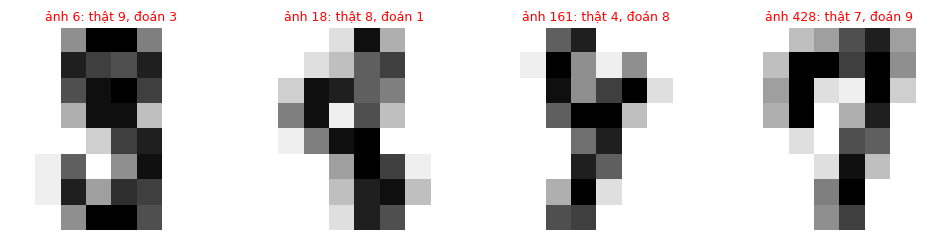

In [11]:
cm = confusion_matrix(yd_te, du_doan)
print("Bang nham lan (hang = that, cot = doan)")
print(pd.DataFrame(cm, index=[f"that {i}" for i in range(10)],
                   columns=[f"d{i}" for i in range(10)]).to_string())

print("\nCac cap bi nham:")
for t in range(10):
    for d in range(10):
        if t != d and cm[t, d] > 0:
            print(f"  that {t} -> doan {d}: {cm[t, d]} anh")

os.makedirs("anh_sai", exist_ok=True)
fig, axs = plt.subplots(1, max(len(sai), 2), figsize=(3 * max(len(sai), 2), 3.3))
for ax, i in zip(np.atleast_1d(axs), sai):
    ax.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"ảnh {i}: thật {yd_te[i]}, đoán {du_doan[i]}", color="red", fontsize=9)
    ax.axis("off")
    plt.imsave(f"anh_sai/anh_{i}_that{yd_te[i]}_doan{du_doan[i]}.png", Xd_te[i].reshape(8, 8), cmap="gray_r")
plt.show()

**Nhận xét:** nhìn các ảnh sai, chữ viết bị nghiêng, nét đứt hoặc dính nhau, và ảnh chỉ có độ phân giải 8×8 nên các cặp có hình dạng gần giống nhau dễ nhầm (ví dụ 9↔3, 7↔9, 8↔1, 4↔8). Đây là những mẫu mà ngay cả người đọc cũng khó chắc chắn.

### Bài tập 6: SVM trên dữ liệu lớn

In [12]:
def do_thoi_gian(mh, X_, y_):
    t0 = time.perf_counter()
    mh.fit(X_, y_)
    return time.perf_counter() - t0

hang = []
for n in [2000, 5000, 10000, 20000]:
    Xb, yb = make_classification(n_samples=n, n_features=20, random_state=0)
    t_svc = do_thoi_gian(SVC(), Xb, yb)
    t_lin = do_thoi_gian(LinearSVC(max_iter=5000), Xb, yb)
    hang.append({"n": n, "SVC (s)": t_svc, "LinearSVC (s)": t_lin})
bt = pd.DataFrame(hang)
bt["SVC tang x"] = bt["SVC (s)"] / bt["SVC (s)"].shift(1)
bt["LinearSVC tang x"] = bt["LinearSVC (s)"] / bt["LinearSVC (s)"].shift(1)
print(bt.round(3).to_string(index=False))

    n  SVC (s)  LinearSVC (s)  SVC tang x  LinearSVC tang x
 2000    0.143          0.015         NaN               NaN
 5000    0.918          0.026       6.418             1.752
10000    5.103          0.036       5.562             1.406
20000   15.614          0.034       3.060             0.940


**Nhận xét:** khi $n$ tăng gấp đôi, thời gian học của `SVC` (kernel) thường tăng khoảng **3–4 lần** vì độ phức tạp xấp xỉ giữa $O(n^2)$ và $O(n^3)$, còn `LinearSVC` chỉ tăng khoảng **2 lần** (gần tuyến tính theo $n$). Vì vậy với dữ liệu lớn, nên thử trên mẫu nhỏ trước hoặc dùng `LinearSVC`. Thời gian tuyệt đối khác nhau giữa các máy, chỉ cần so tương đối.